# Disease Prediction System (Healthcare AI)

**Objective:** Predict likely diseases from a patient's symptoms and basic medical record values.
**Tech:** Python, Scikit-learn (KNN, Random Forest), Pandas, Seaborn.

**Pipeline**
1. Build / load the dataset
2. Explore the data
3. Normalize the medical data
4. Select crucial features with a correlation matrix
5. Train a tuned **KNN** model (Random Forest as a benchmark)
6. Evaluate
7. Interactive predictor: enter symptoms, get disease likelihoods

> **Note on data:** This notebook generates a *synthetic* dataset so it runs anywhere with no downloads. To use real data (e.g. the Kaggle *Disease Symptom Prediction* dataset), replace the single cell in Step 1 with `df = pd.read_csv("your_file.csv")` and keep a column named `disease`. Everything after it works unchanged.
>
> **Disclaimer:** Educational project only. Not a medical device and not a substitute for a doctor.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Libraries loaded")

Libraries loaded


## 1. Dataset
Each row is one patient: binary symptom flags (1 = present) + numeric medical record values + the diagnosed `disease`.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)

SYMPTOMS = ["fever","cough","sore_throat","runny_nose","headache","fatigue","body_ache","nausea",
            "vomiting","diarrhea","abdominal_pain","chest_pain","shortness_of_breath","rash",
            "joint_pain","chills","loss_of_taste_smell","frequent_urination","excessive_thirst",
            "blurred_vision","dizziness","sweating","itching","yellow_skin","loss_of_appetite",
            "stiff_neck","light_sensitivity"]
NUMERIC = ["age","temperature_f","heart_rate","systolic_bp","wbc_count"]

# Each disease: symptom probabilities + (mean, std) of the numeric record values
PROFILES = {
 "Common Cold":     ({"runny_nose":.9,"sore_throat":.7,"cough":.6,"headache":.3,"fatigue":.3},
                     dict(age=(30,15),temperature_f=(98.9,.5),heart_rate=(76,8),systolic_bp=(118,10),wbc_count=(7,1.2))),
 "Influenza":       ({"fever":.9,"chills":.7,"body_ache":.9,"cough":.8,"headache":.6,"fatigue":.8,"sore_throat":.4},
                     dict(age=(32,16),temperature_f=(101.5,.9),heart_rate=(90,9),systolic_bp=(116,10),wbc_count=(6,1.2))),
 "COVID-19":        ({"fever":.8,"cough":.8,"loss_of_taste_smell":.8,"fatigue":.7,"shortness_of_breath":.4,
                      "body_ache":.5,"headache":.5,"sore_throat":.4},
                     dict(age=(42,17),temperature_f=(100.6,1),heart_rate=(88,10),systolic_bp=(120,12),wbc_count=(5.5,1.5))),
 "Pneumonia":       ({"fever":.85,"cough":.95,"shortness_of_breath":.8,"chest_pain":.6,"chills":.6,"fatigue":.6},
                     dict(age=(55,20),temperature_f=(101.8,1),heart_rate=(100,10),systolic_bp=(118,12),wbc_count=(14,2.5))),
 "Dengue":          ({"fever":.95,"headache":.8,"joint_pain":.85,"body_ache":.8,"rash":.6,"nausea":.5,
                      "vomiting":.4,"fatigue":.7,"light_sensitivity":.3},
                     dict(age=(28,13),temperature_f=(103,1),heart_rate=(92,9),systolic_bp=(110,10),wbc_count=(3.2,.9))),
 "Malaria":         ({"fever":.95,"chills":.9,"sweating":.8,"headache":.7,"nausea":.5,"vomiting":.4,
                      "body_ache":.5,"fatigue":.6},
                     dict(age=(30,14),temperature_f=(102.5,1),heart_rate=(96,10),systolic_bp=(108,10),wbc_count=(5,1.3))),
 "Typhoid":         ({"fever":.9,"abdominal_pain":.7,"headache":.6,"loss_of_appetite":.7,"fatigue":.7,
                      "diarrhea":.4,"nausea":.4,"rash":.25},
                     dict(age=(26,12),temperature_f=(102,1),heart_rate=(80,8),systolic_bp=(110,10),wbc_count=(4.5,1.2))),
 "Gastroenteritis": ({"diarrhea":.9,"vomiting":.8,"nausea":.85,"abdominal_pain":.8,"fever":.4,"fatigue":.4},
                     dict(age=(30,18),temperature_f=(99.5,.9),heart_rate=(92,10),systolic_bp=(112,11),wbc_count=(9,2))),
 "Diabetes":        ({"excessive_thirst":.9,"frequent_urination":.9,"fatigue":.7,"blurred_vision":.6,
                      "itching":.3,"dizziness":.3},
                     dict(age=(52,12),temperature_f=(98.6,.4),heart_rate=(80,9),systolic_bp=(132,13),wbc_count=(7.5,1.5))),
 "Hypertension":    ({"headache":.6,"dizziness":.6,"blurred_vision":.3,"chest_pain":.25,
                      "shortness_of_breath":.25,"fatigue":.35},
                     dict(age=(56,11),temperature_f=(98.6,.4),heart_rate=(82,10),systolic_bp=(160,14),wbc_count=(7,1.4))),
 "Migraine":        ({"headache":.98,"nausea":.7,"light_sensitivity":.9,"vomiting":.4,"dizziness":.4,"blurred_vision":.3},
                     dict(age=(34,10),temperature_f=(98.6,.4),heart_rate=(78,9),systolic_bp=(118,10),wbc_count=(7,1.3))),
 "Hepatitis":       ({"yellow_skin":.95,"fatigue":.8,"loss_of_appetite":.8,"nausea":.6,"abdominal_pain":.5,
                      "itching":.5,"fever":.3,"vomiting":.4},
                     dict(age=(38,14),temperature_f=(99.2,.8),heart_rate=(80,9),systolic_bp=(115,11),wbc_count=(6.5,1.6))),
 "Asthma":          ({"shortness_of_breath":.95,"cough":.8,"chest_pain":.4,"fatigue":.3},
                     dict(age=(28,15),temperature_f=(98.6,.4),heart_rate=(92,10),systolic_bp=(118,10),wbc_count=(8,1.5))),
 "Meningitis":      ({"fever":.9,"headache":.95,"stiff_neck":.9,"light_sensitivity":.8,"nausea":.6,"vomiting":.5},
                     dict(age=(25,15),temperature_f=(102.5,1),heart_rate=(104,10),systolic_bp=(115,11),wbc_count=(16,3))),
}

N_PER_DISEASE, NOISE = 400, 0.04     # NOISE = chance of an unrelated symptom appearing
rows = []
for disease, (sym_p, num_p) in PROFILES.items():
    for _ in range(N_PER_DISEASE):
        r = {s: int(rng.random() < sym_p.get(s, NOISE)) for s in SYMPTOMS}
        for col, (mu, sd) in num_p.items():
            r[col] = rng.normal(mu, sd)
        r["age"] = int(np.clip(r["age"], 1, 95))
        r["disease"] = disease
        rows.append(r)

df = pd.DataFrame(rows).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
print(df.shape)
df.head()

(5600, 33)


,fever,cough,sore_throat,runny_nose,headache,fatigue,body_ache,nausea,vomiting,diarrhea,...,yellow_skin,loss_of_appetite,stiff_neck,light_sensitivity,age,temperature_f,heart_rate,systolic_bp,wbc_count,disease
0,0,0,0,0,0,1,0,1,0,0,...,1,0,0,0,10,98.547743,72.297255,123.790016,7.851404,Hepatitis
1,0,0,0,0,1,0,0,1,0,0,...,0,0,0,1,30,98.554448,78.607974,115.327506,5.912650,Migraine
2,1,0,0,0,1,1,0,0,0,0,...,0,0,0,0,25,102.698047,89.514420,95.162933,5.974841,Malaria
3,1,1,0,0,1,1,0,0,1,0,...,0,1,0,0,16,102.385289,95.696906,112.155879,4.906226,Typhoid
4,0,0,0,0,1,1,0,1,1,1,...,0,0,0,0,29,99.409201,102.376646,100.720865,9.017083,Gastroenteritis


## 2. Quick exploration

Missing values: 0
Diseases: 14 | Symptoms: 27 | Numeric record fields: 5


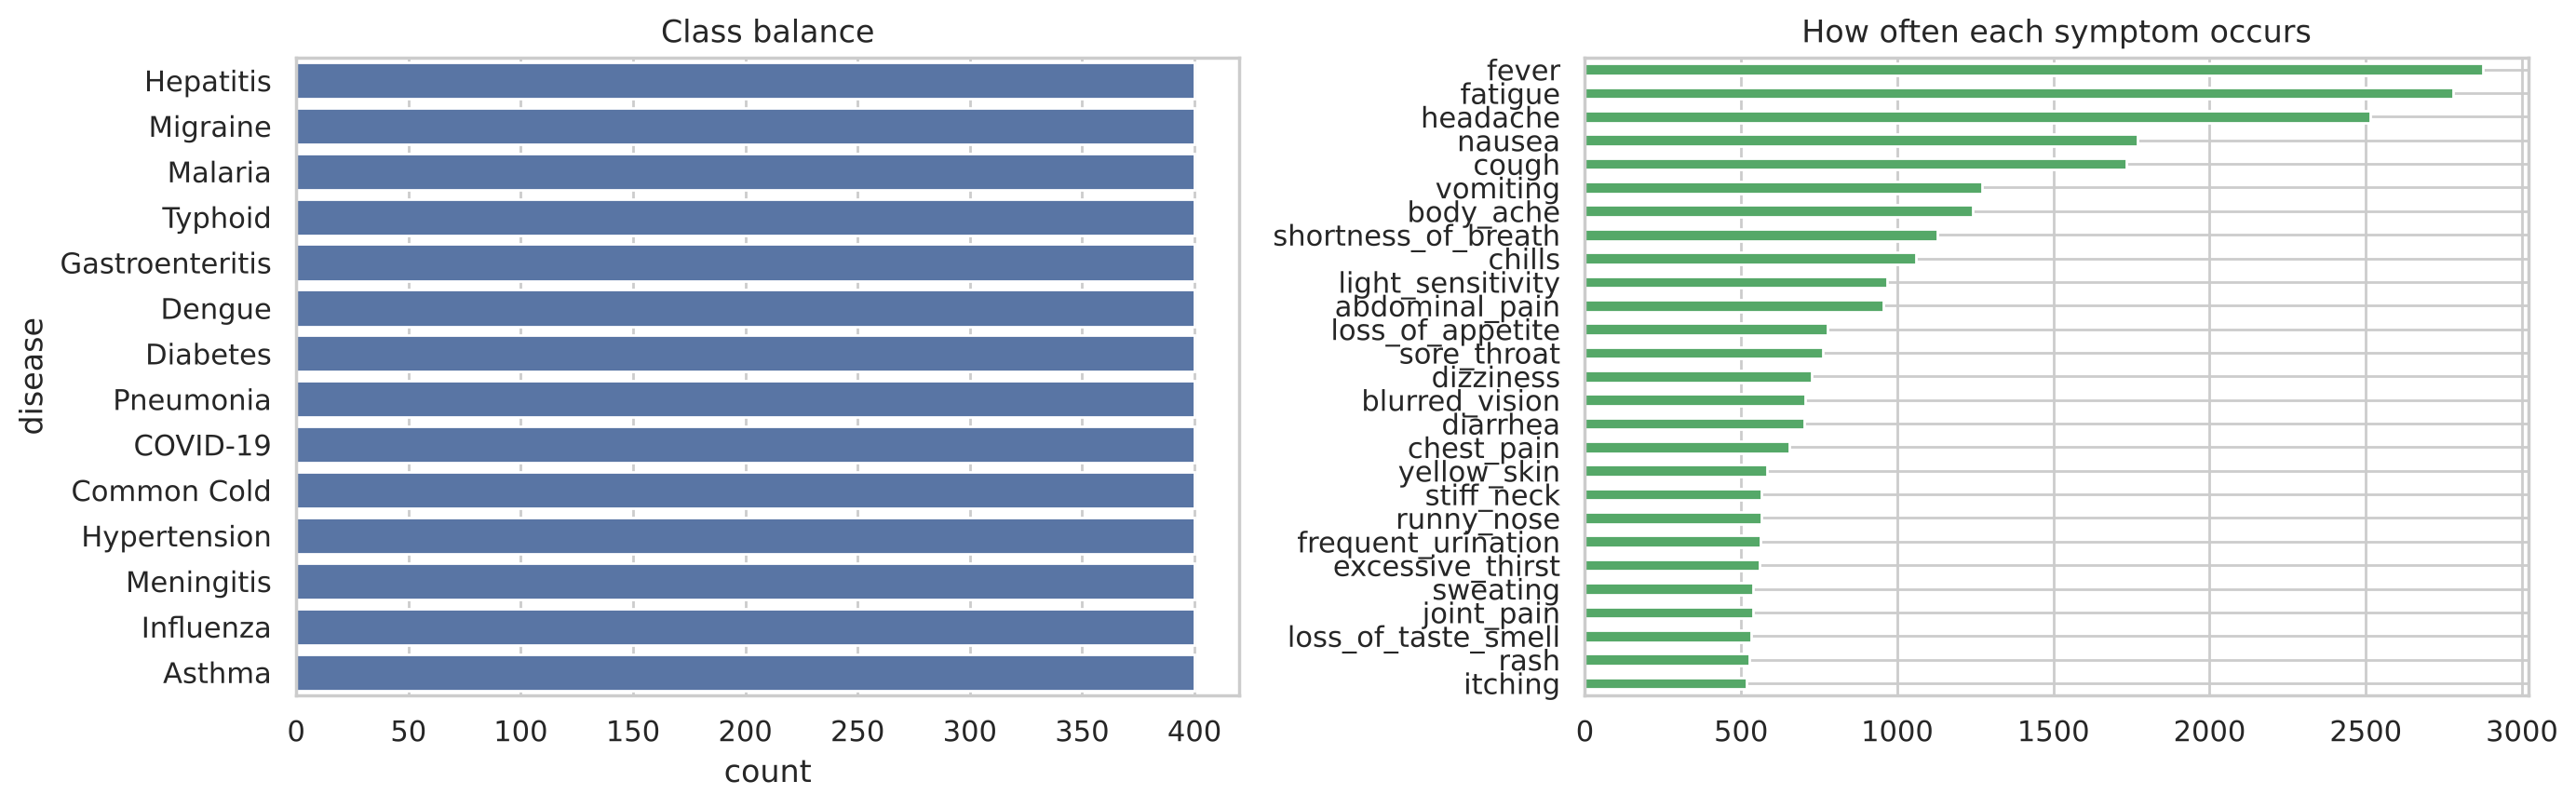

In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("Diseases:", df["disease"].nunique(), "| Symptoms:", len(SYMPTOMS), "| Numeric record fields:", len(NUMERIC))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.countplot(y="disease", data=df, order=df["disease"].value_counts().index, ax=ax[0], color="#4C72B0")
ax[0].set_title("Class balance")
df[SYMPTOMS].sum().sort_values().plot.barh(ax=ax[1], color="#55A868")
ax[1].set_title("How often each symptom occurs")
plt.tight_layout(); plt.show()

## 3. Normalize the medical data
Symptom columns are already 0/1. The numeric record values live on very different scales (age ≈ 0–95, WBC ≈ 3–16, blood pressure ≈ 100–160), and **KNN is distance-based**, so large-scale columns would drown out the rest. We standardize them (zero mean, unit variance).

The scaler is fit on the **training split only**, to avoid data leakage.

In [4]:
X = df[SYMPTOMS + NUMERIC].copy()
y = df["disease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

scaler = StandardScaler().fit(X_train[NUMERIC])

def normalize(frame):
    out = frame.copy()
    out[NUMERIC] = scaler.transform(frame[NUMERIC])
    return out

X_train_n, X_test_n = normalize(X_train), normalize(X_test)

print("Before:"); display(X_train[NUMERIC].describe().loc[["mean","std","min","max"]].round(2))
print("After:");  display(X_train_n[NUMERIC].describe().loc[["mean","std","min","max"]].round(2))

Before:


,age,temperature_f,heart_rate,systolic_bp,wbc_count
mean,35.74,100.42,87.93,119.30,7.64
std,17.64,1.86,12.71,16.68,3.79
min,1.00,97.18,50.78,75.80,0.87
max,95.00,105.96,136.76,196.98,30.73


After:


,age,temperature_f,heart_rate,systolic_bp,wbc_count
mean,-0.00,-0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-1.97,-1.75,-2.92,-2.61,-1.78
max,3.36,2.98,3.84,4.66,6.09


## 4. Feature selection with correlation matrices
Two checks on the **training data**:

1. **Feature ↔ disease correlation**: how strongly does each feature relate to each disease (one-vs-rest)? Features with a weak link to *every* disease are not useful.
2. **Feature ↔ feature correlation**: if two features are almost identical (|r| > 0.85), keep only one to remove redundancy.

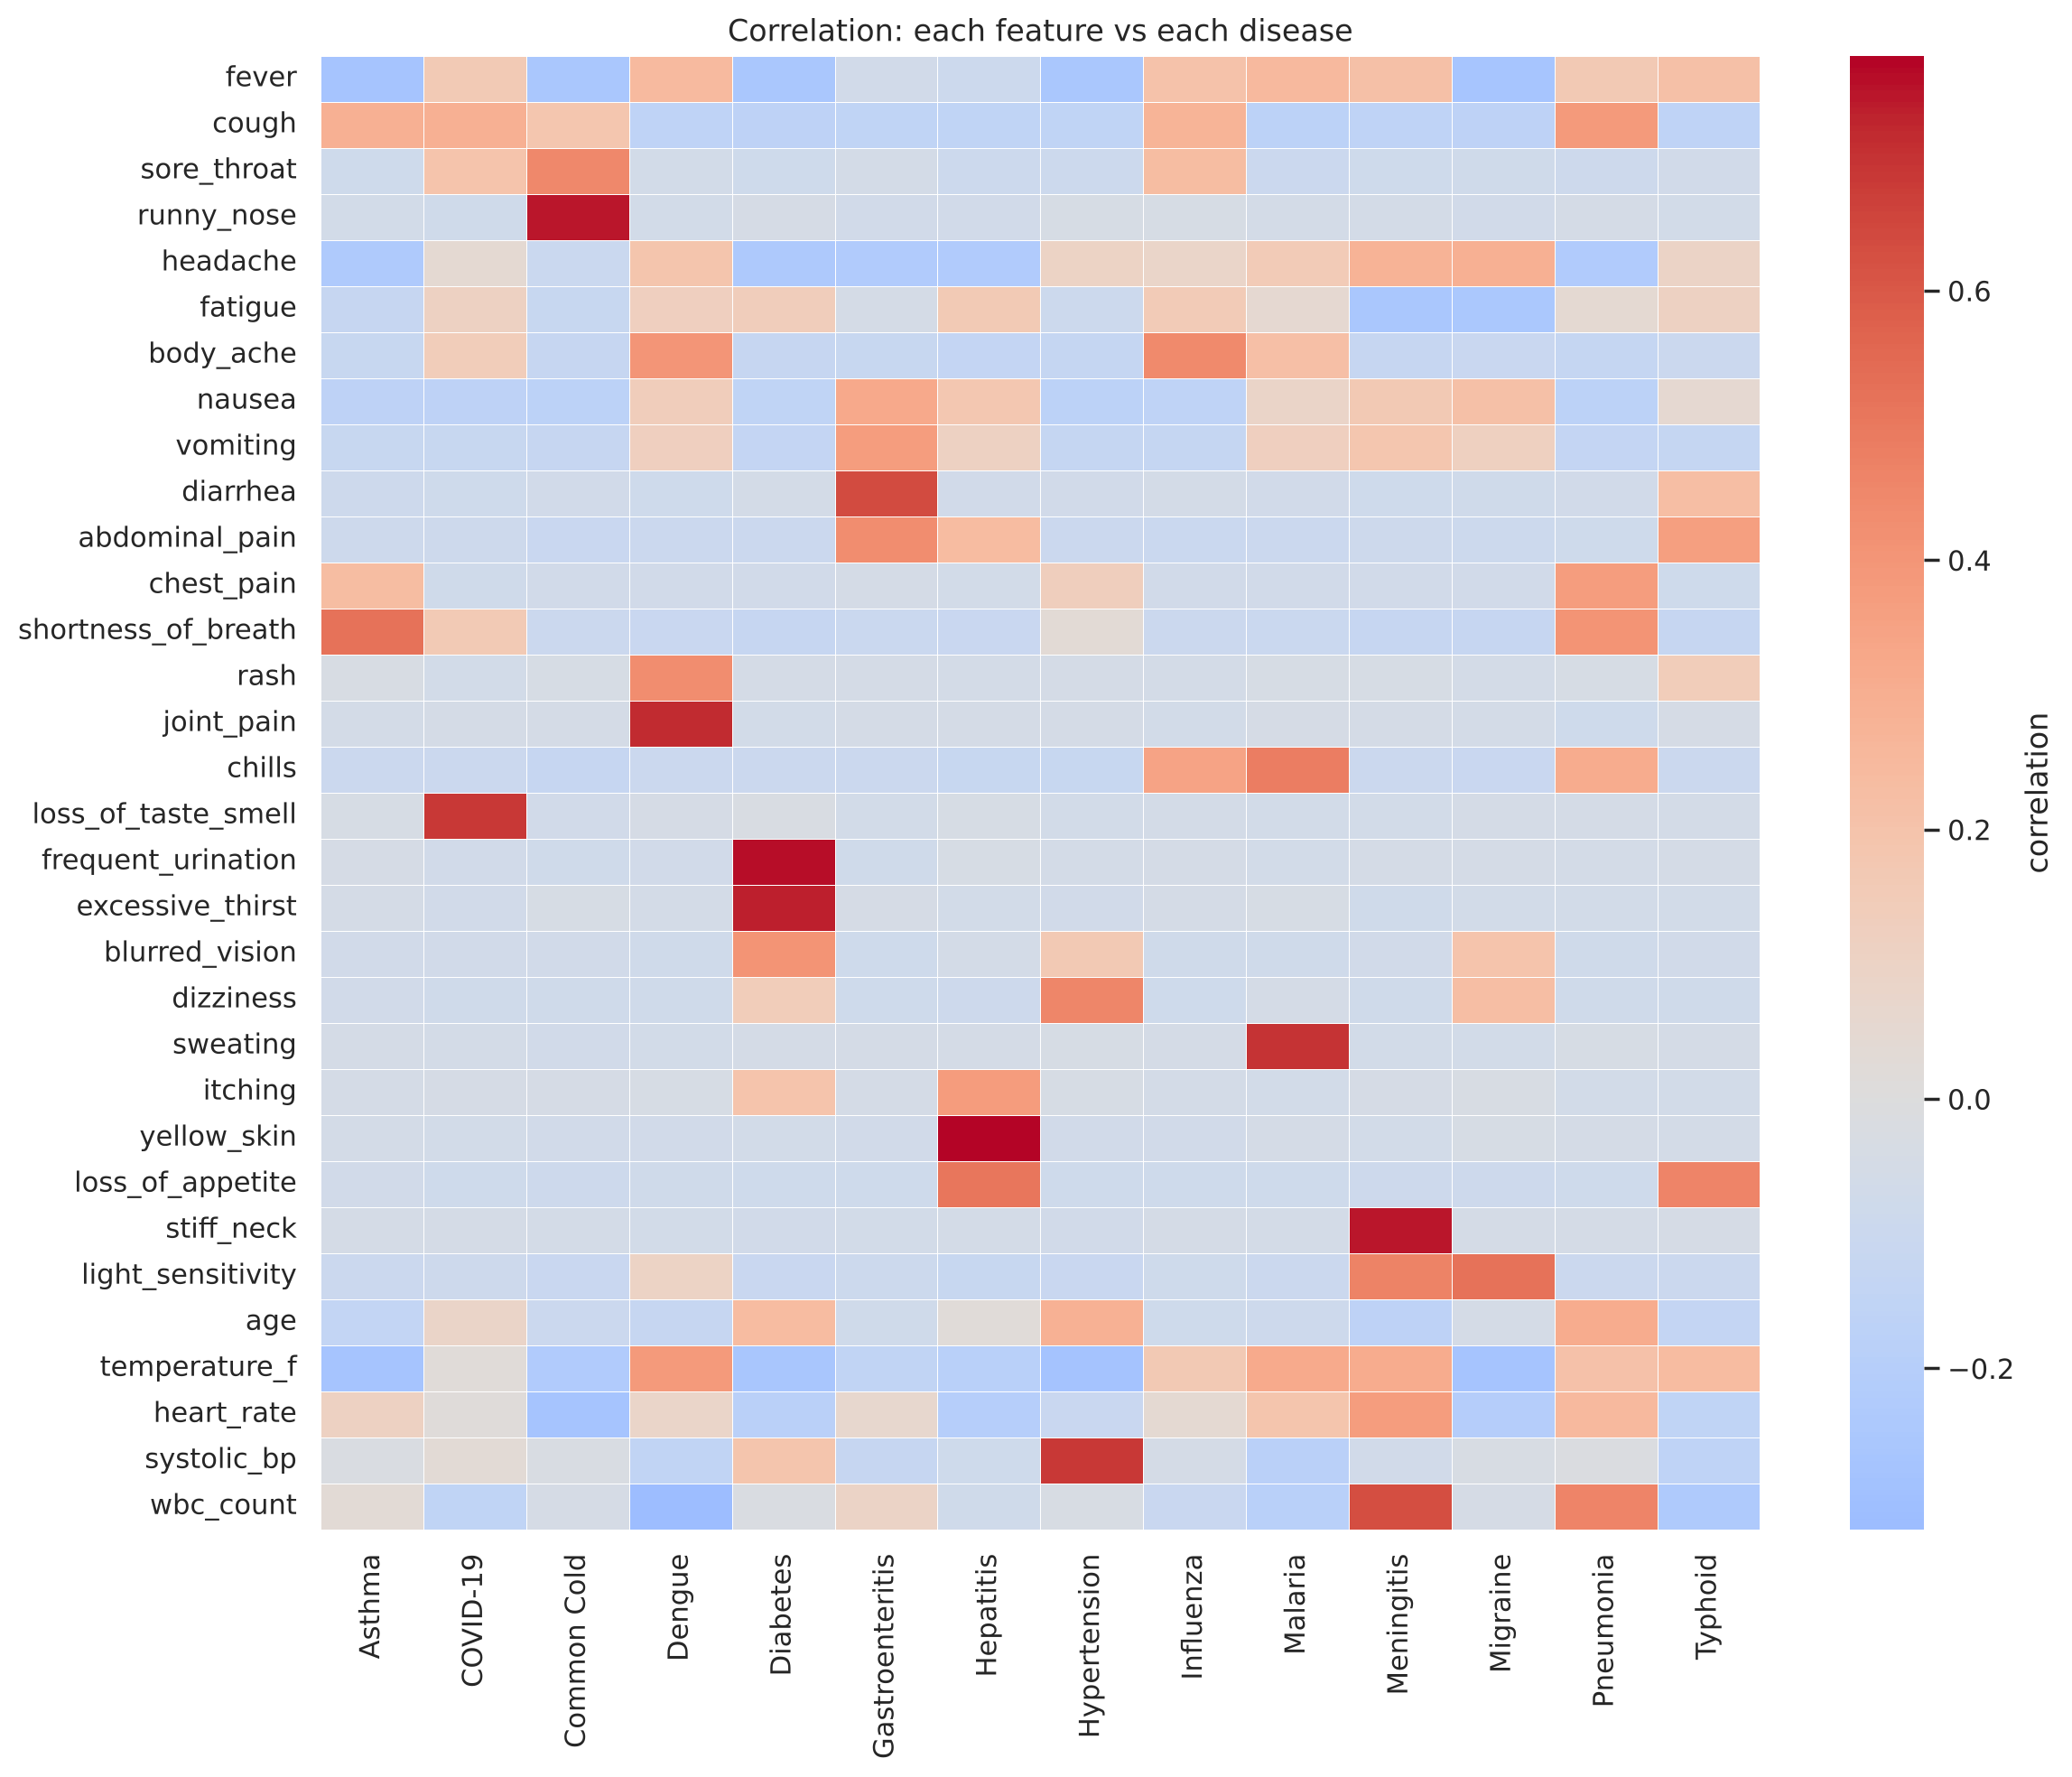

In [5]:
Y_dummies = pd.get_dummies(y_train).astype(float)
feat_vs_disease = pd.concat([X_train_n, Y_dummies], axis=1).corr().loc[X_train_n.columns, Y_dummies.columns]

plt.figure(figsize=(12, 10))
sns.heatmap(feat_vs_disease, cmap="coolwarm", center=0, linewidths=.3, cbar_kws={"label": "correlation"})
plt.title("Correlation: each feature vs each disease"); plt.tight_layout(); plt.show()

,threshold,n_features,cv_accuracy
0,0.00,32,0.964
1,0.25,32,0.964
2,0.30,29,0.958
3,0.35,27,0.950
4,0.40,21,0.895
5,0.45,16,0.848
6,0.50,14,0.829


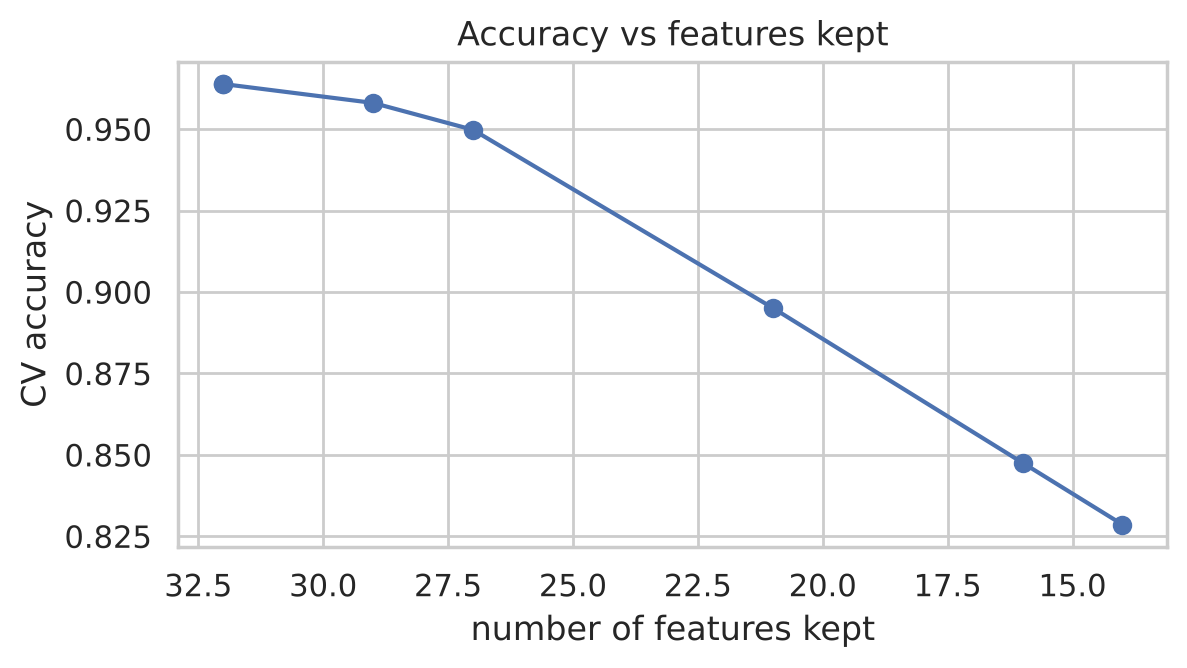

Kept 29 of 32 features | dropped weak: ['fatigue', 'fever', 'headache'] | dropped redundant: []


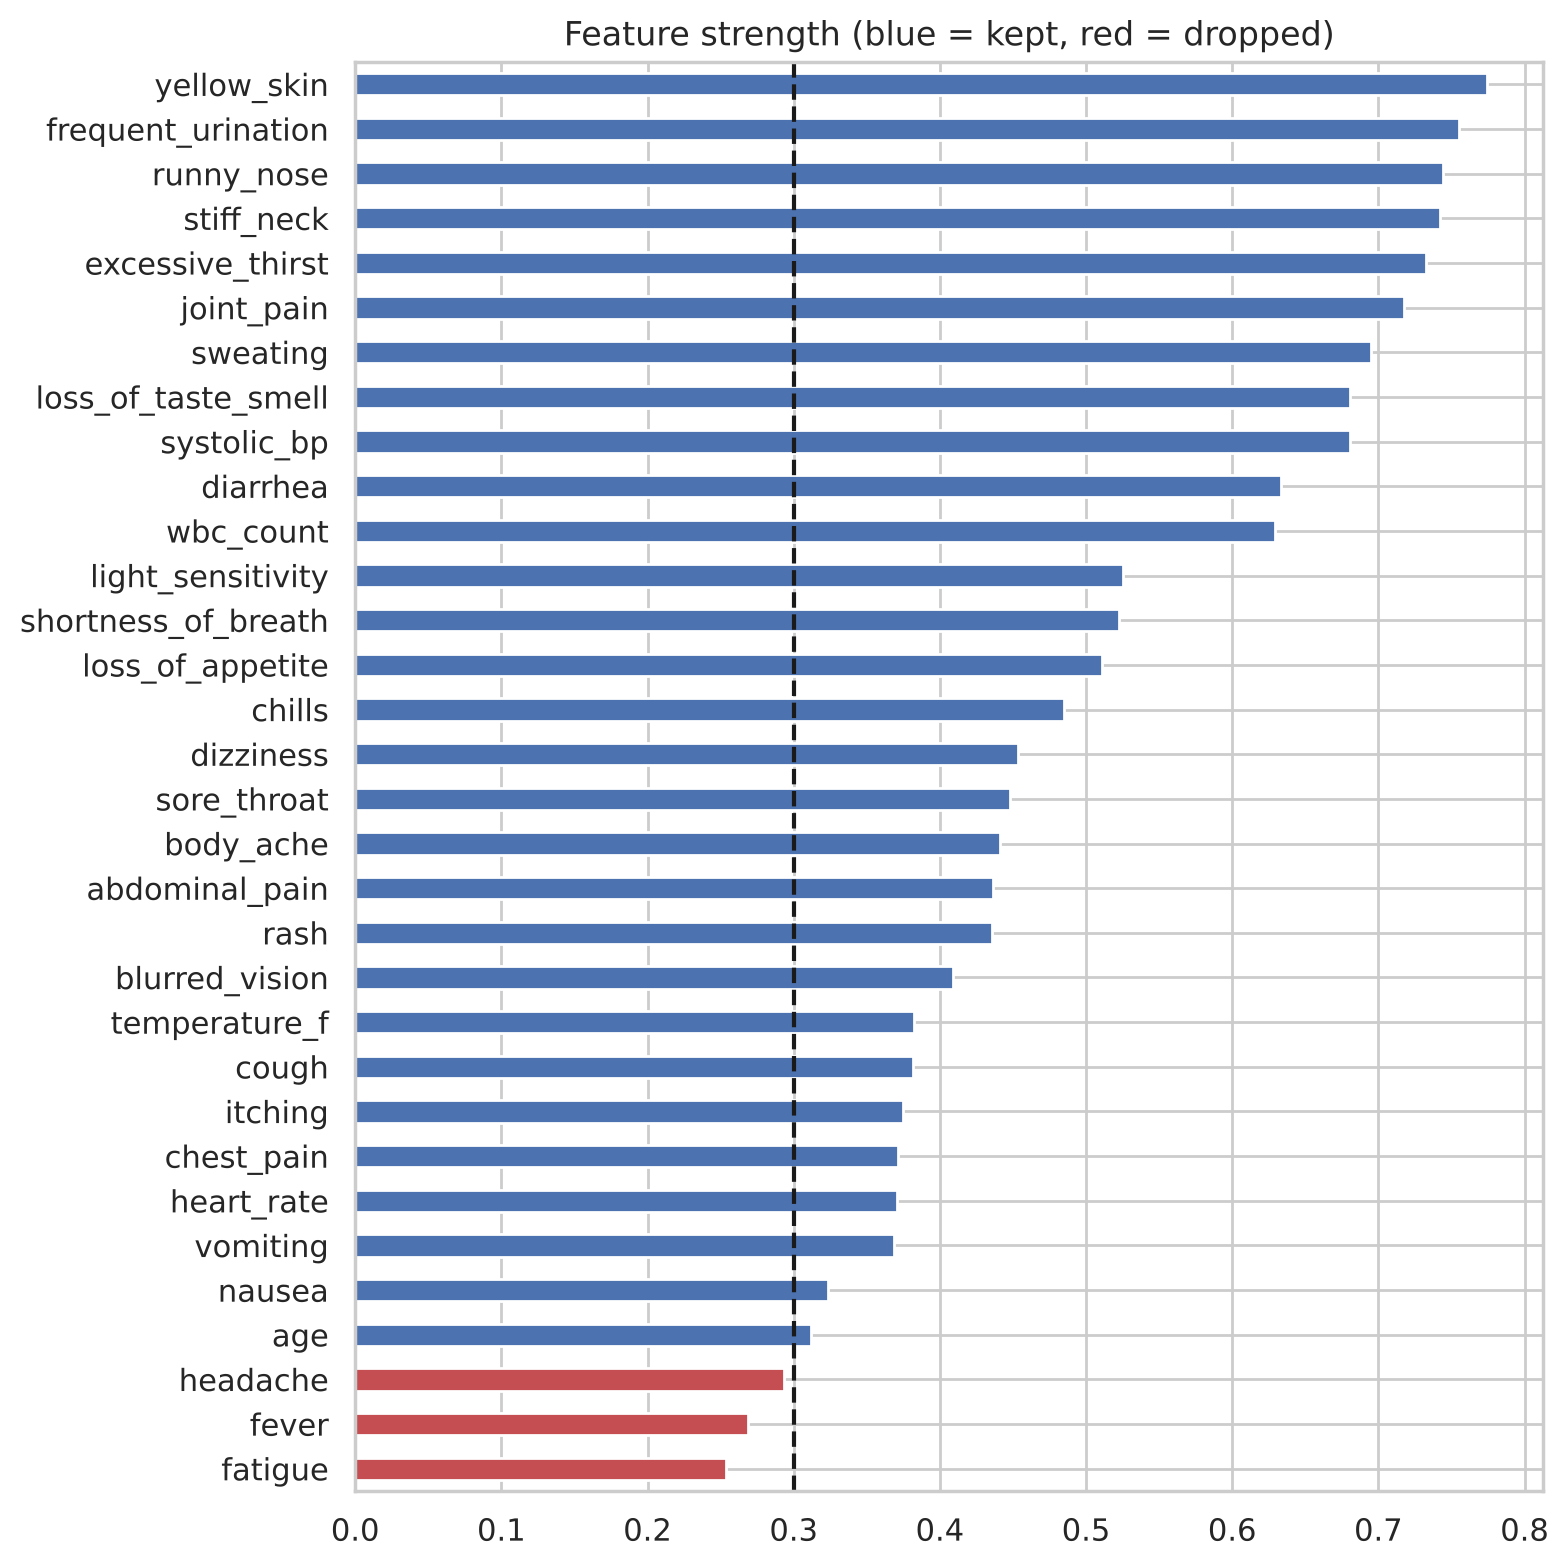

In [6]:
# Strength = strongest correlation a feature has with ANY disease
strength = feat_vs_disease.abs().max(axis=1).sort_values(ascending=False)

# Don't guess the cut-off: test how accuracy changes as weaker features are dropped
sweep = []
for t in [0.0, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    feats = strength[strength >= t].index.tolist()
    acc = cross_val_score(KNeighborsClassifier(15, metric="manhattan"), X_train_n[feats], y_train, cv=5).mean()
    sweep.append((t, len(feats), acc))
sweep = pd.DataFrame(sweep, columns=["threshold", "n_features", "cv_accuracy"])
display(sweep.round(3))
plt.figure(figsize=(6, 3.5)); plt.plot(sweep.n_features, sweep.cv_accuracy, "o-")
plt.xlabel("number of features kept"); plt.ylabel("CV accuracy"); plt.title("Accuracy vs features kept")
plt.gca().invert_xaxis(); plt.tight_layout(); plt.show()

# 0.30 removes the weakest features with under 1% accuracy loss; going higher starts to hurt
THRESHOLD = 0.30
selected = strength[strength >= THRESHOLD].index.tolist()

# Redundancy check among the kept features
fcorr = X_train_n[selected].corr().abs()
upper = fcorr.where(np.triu(np.ones(fcorr.shape), k=1).astype(bool))
redundant = [c for c in upper.columns if (upper[c] > 0.85).any()]
selected = [c for c in selected if c not in redundant]

print(f"Kept {len(selected)} of {X_train_n.shape[1]} features | dropped weak: "
      f"{sorted(set(strength.index) - set(selected) - set(redundant))} | dropped redundant: {redundant}")

plt.figure(figsize=(8, 8))
strength.plot.barh(color=["#C44E52" if f not in selected else "#4C72B0" for f in strength.index]).invert_yaxis()
plt.axvline(THRESHOLD, ls="--", c="k"); plt.title("Feature strength (blue = kept, red = dropped)")
plt.tight_layout(); plt.show()

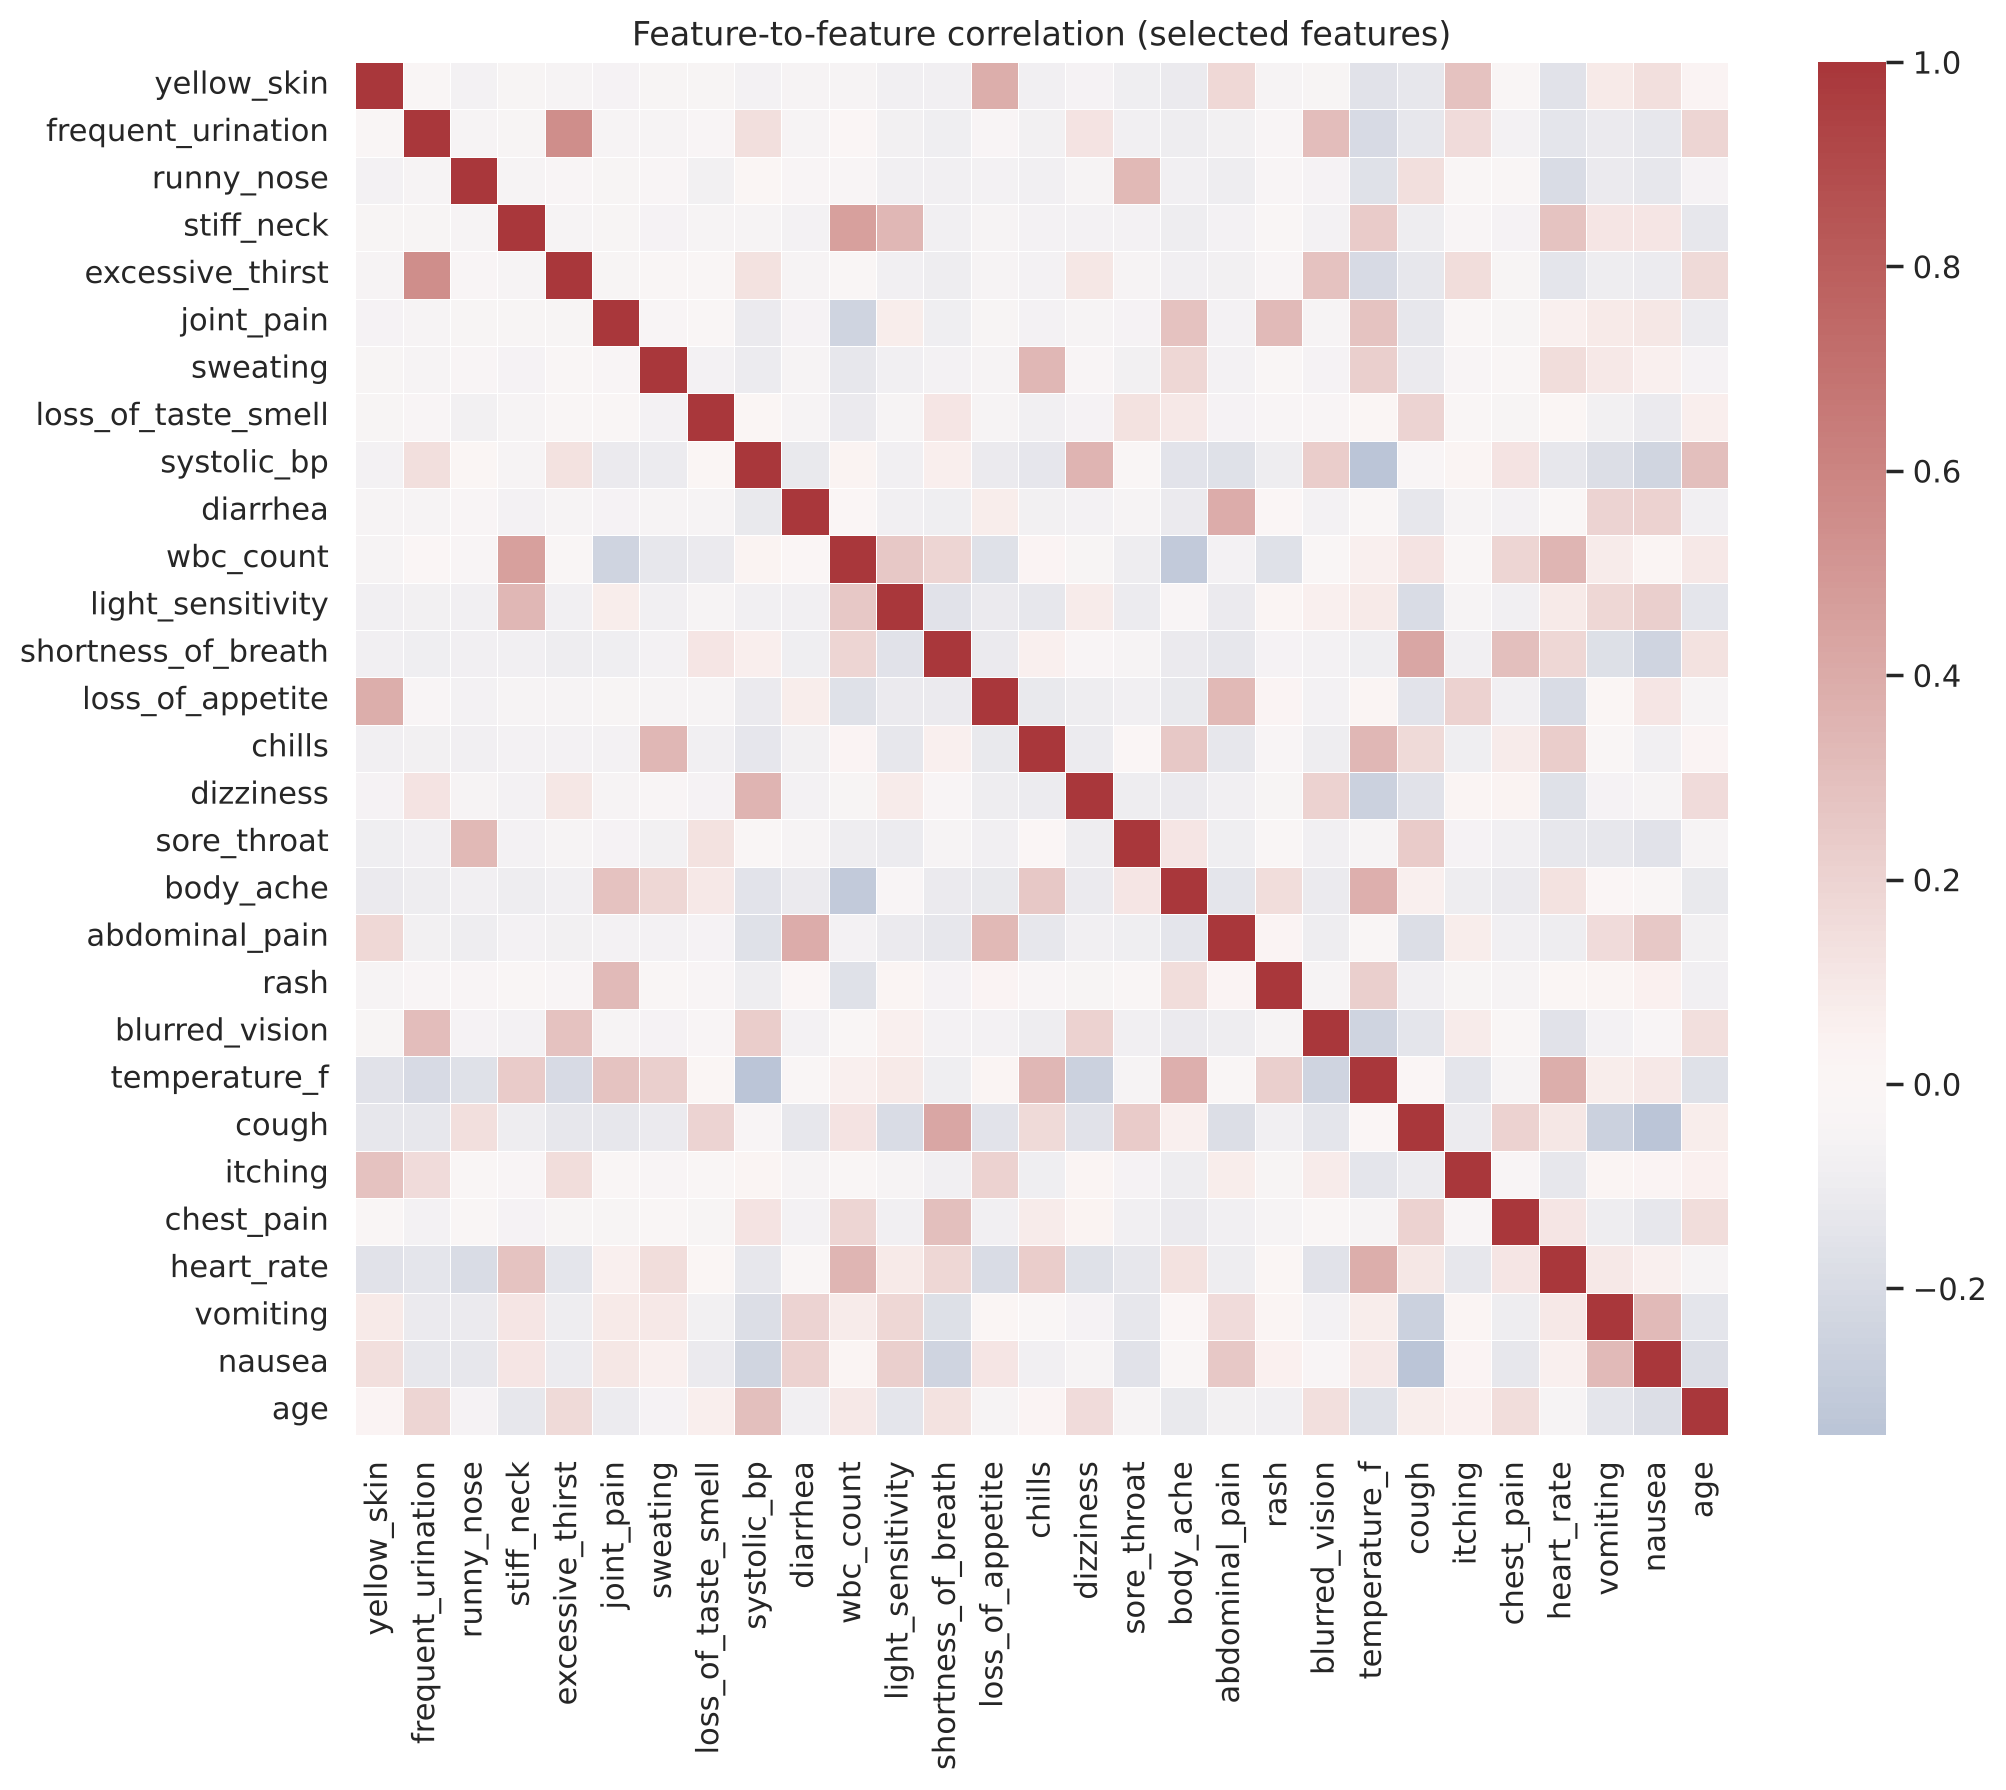

In [7]:
plt.figure(figsize=(11, 9))
sns.heatmap(X_train_n[selected].corr(), cmap="vlag", center=0, square=True, linewidths=.2)
plt.title("Feature-to-feature correlation (selected features)"); plt.tight_layout(); plt.show()

## 5. Build the KNN model
We tune `k` and the distance metric with 5-fold cross-validation on the training set.

In [8]:
param_grid = {"n_neighbors": [3, 5, 7, 9, 11, 15, 21],
              "weights": ["uniform"],   # uniform voting gives graded probabilities (distance weighting gives 0%/100%)
              "metric": ["euclidean", "manhattan"]}

grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train_n[selected], y_train)
knn = grid.best_estimator_

print("Best parameters :", grid.best_params_)
print(f"CV accuracy     : {grid.best_score_:.3f}")

Best parameters : {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'uniform'}
CV accuracy     : 0.959


## 6. Evaluation

KNN test accuracy: 0.960

                 precision    recall  f1-score   support

         Asthma       0.89      0.95      0.92        80
       COVID-19       0.92      0.89      0.90        80
    Common Cold       0.90      0.94      0.92        80
         Dengue       0.99      0.99      0.99        80
       Diabetes       0.99      0.99      0.99        80
Gastroenteritis       1.00      0.99      0.99        80
      Hepatitis       0.99      0.95      0.97        80
   Hypertension       0.96      0.97      0.97        80
      Influenza       0.91      0.93      0.92        80
        Malaria       0.99      0.95      0.97        80
     Meningitis       1.00      1.00      1.00        80
       Migraine       0.95      0.99      0.97        80
      Pneumonia       1.00      0.96      0.98        80
        Typhoid       0.95      0.95      0.95        80

       accuracy                           0.96      1120
      macro avg       0.96      0.96      0.96      1120
   

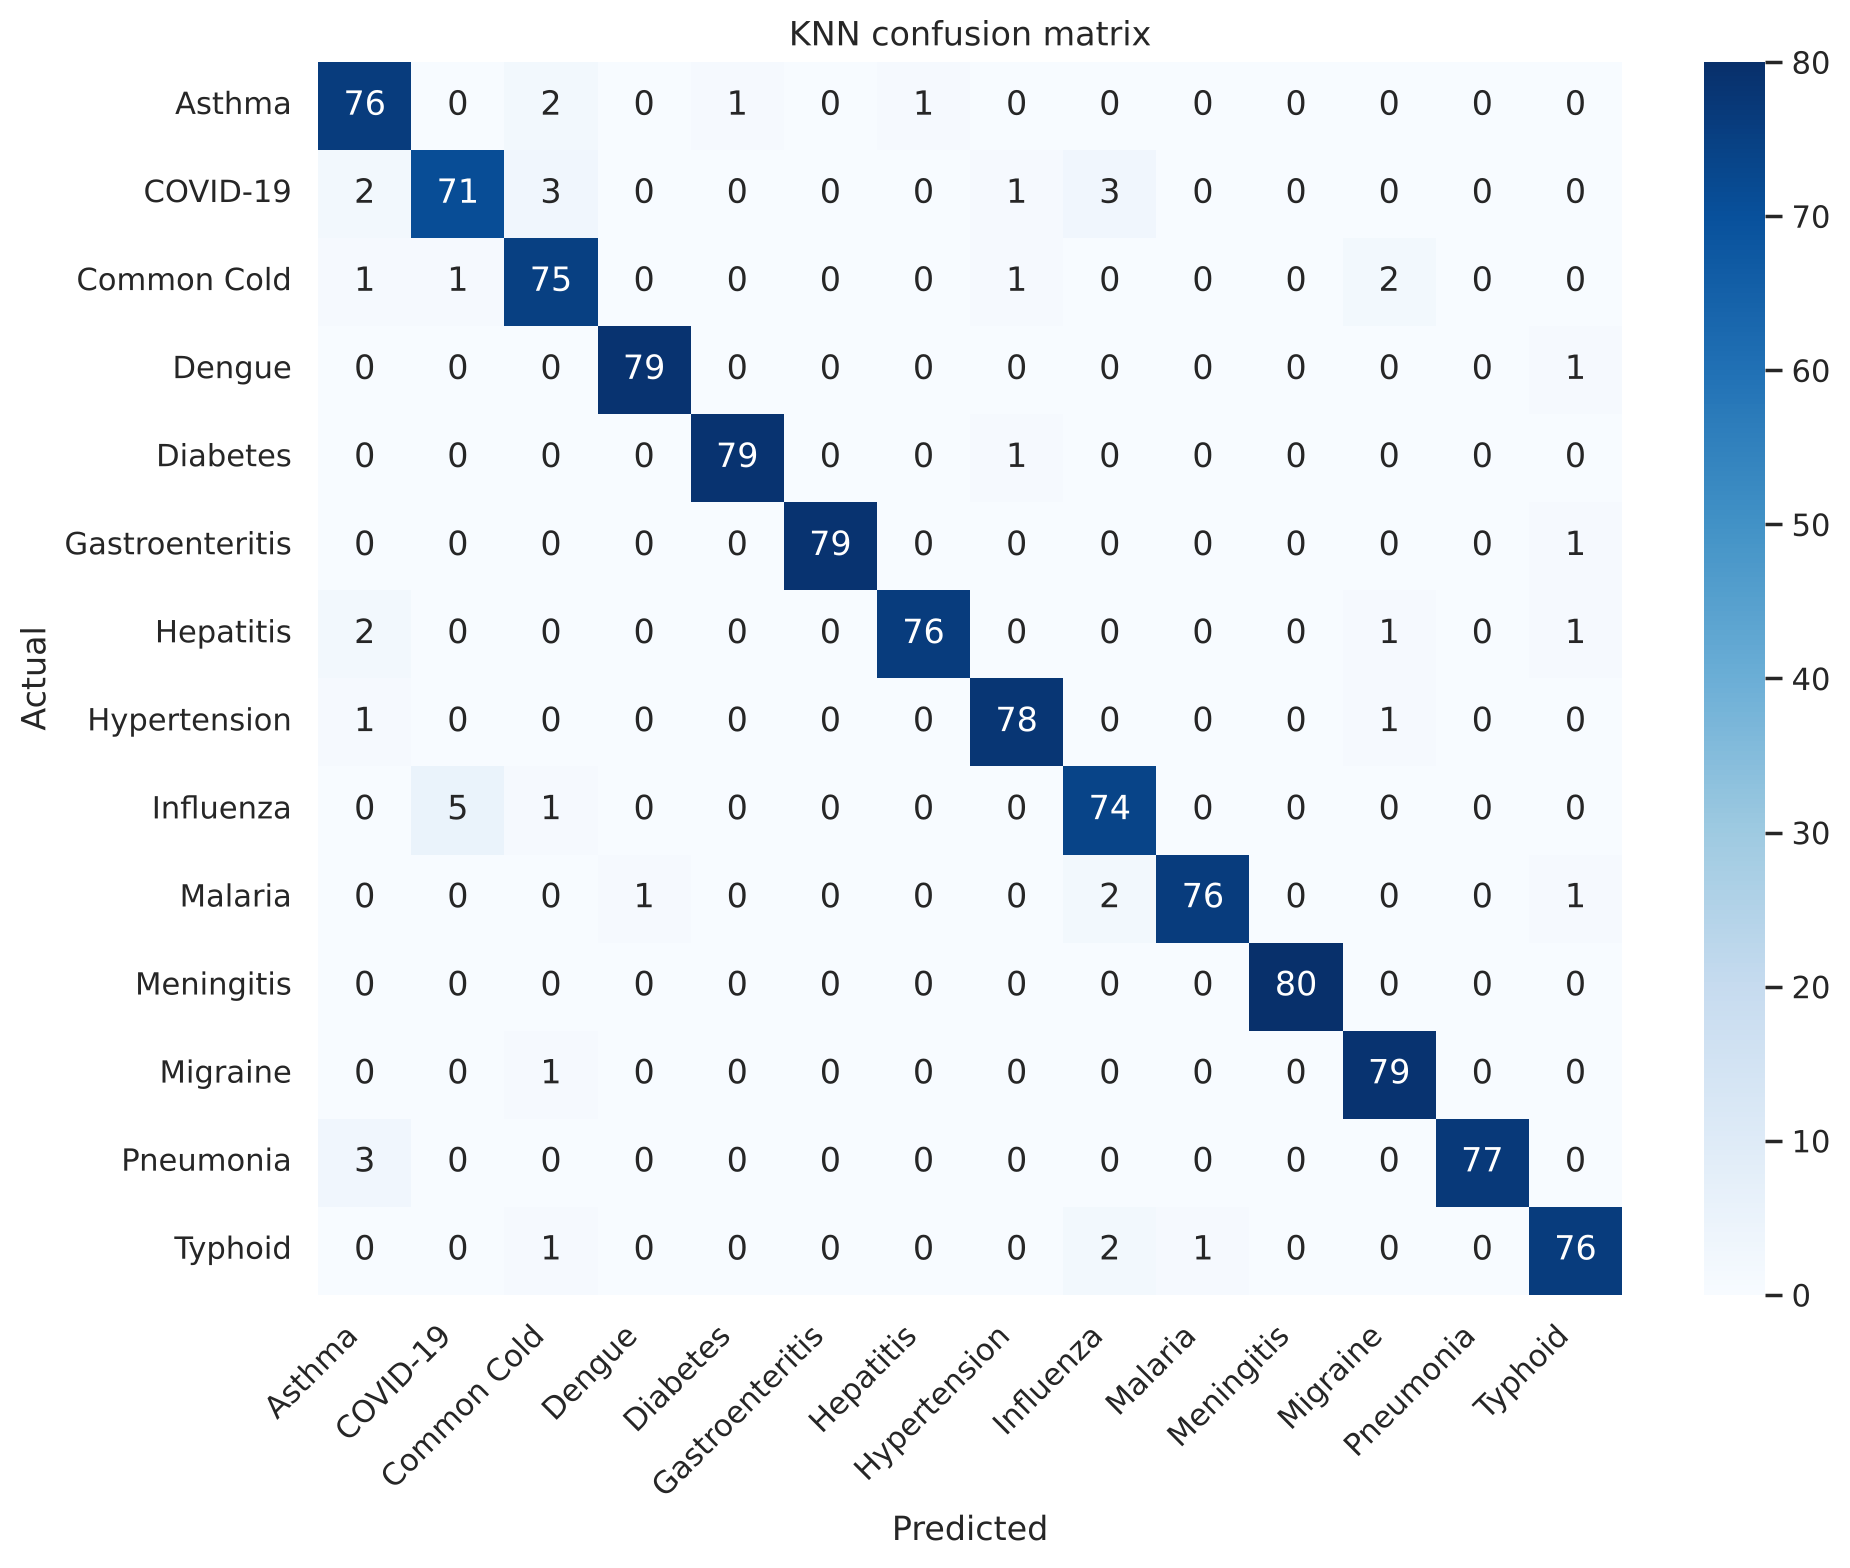

In [9]:
knn_pred = knn.predict(X_test_n[selected])
print(f"KNN test accuracy: {accuracy_score(y_test, knn_pred):.3f}\n")
print(classification_report(y_test, knn_pred))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, knn_pred, labels=labels)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("KNN confusion matrix")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

KNN test accuracy          : 0.960
Random Forest test accuracy: 0.964


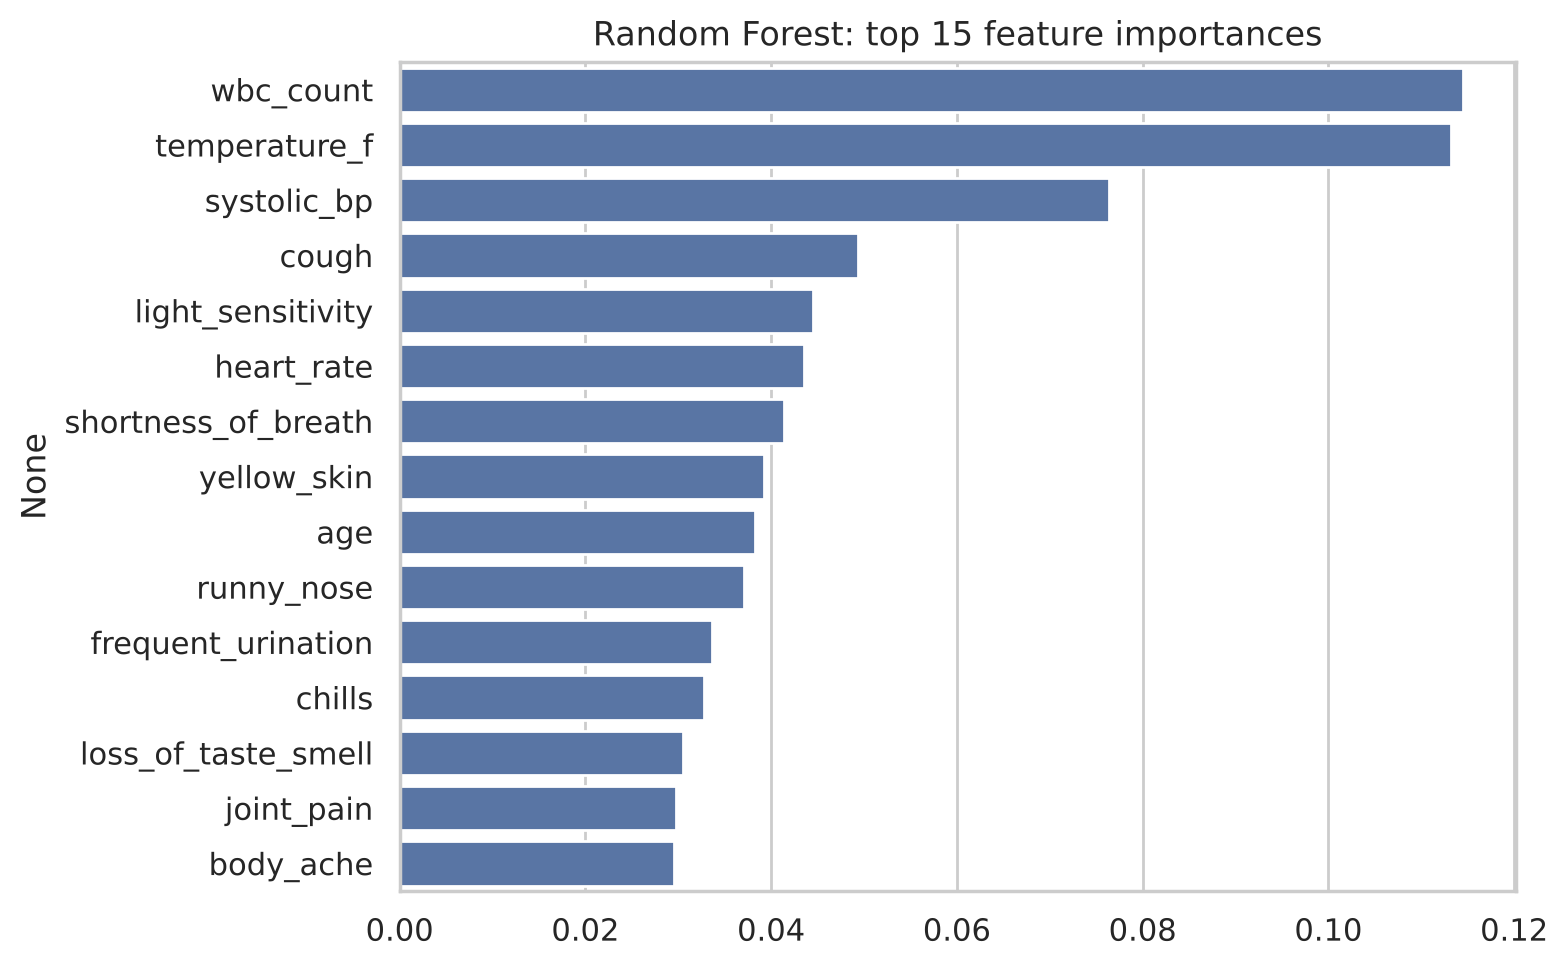

In [10]:
# Benchmark: Random Forest on the same features
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train_n[selected], y_train)
rf_acc = accuracy_score(y_test, rf.predict(X_test_n[selected]))
knn_acc = accuracy_score(y_test, knn_pred)

print(f"KNN test accuracy          : {knn_acc:.3f}")
print(f"Random Forest test accuracy: {rf_acc:.3f}")

imp = pd.Series(rf.feature_importances_, index=selected).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5)); sns.barplot(x=imp.values, y=imp.index, color="#4C72B0")
plt.title("Random Forest: top 15 feature importances"); plt.tight_layout(); plt.show()

## 7. Interactive predictor
`predict_disease()` takes the symptoms a patient has (plus optional record values) and returns the **likelihood of each disease**, using KNN's neighbour vote (`predict_proba`).

If a numeric value is not supplied, the training-set median is used.

In [11]:
MEDIANS = X_train[NUMERIC].median().to_dict()

def predict_disease(symptoms, age=None, temperature_f=None, heart_rate=None,
                    systolic_bp=None, wbc_count=None, top_n=3, verbose=True):
    """symptoms: list of symptom names, e.g. ["fever", "joint pain", "rash"]"""
    names = [s.strip().lower().replace(" ", "_") for s in symptoms]
    unknown = [s for s in names if s not in SYMPTOMS]
    if unknown:
        print("Ignored unknown symptoms:", unknown)

    row = {s: int(s in names) for s in SYMPTOMS}
    given = dict(age=age, temperature_f=temperature_f, heart_rate=heart_rate,
                 systolic_bp=systolic_bp, wbc_count=wbc_count)
    for k in NUMERIC:
        row[k] = given[k] if given[k] is not None else MEDIANS[k]

    x = normalize(pd.DataFrame([row])[SYMPTOMS + NUMERIC])[selected]
    proba = pd.Series(knn.predict_proba(x)[0], index=knn.classes_).sort_values(ascending=False)

    if verbose:
        print("Symptoms entered:", ", ".join(names) or "none")
        print("-" * 46)
        for disease, p in proba.head(top_n).items():
            print(f"{disease:<17} {p*100:5.1f}%  {'#' * int(p*30)}")
        print("-" * 46)
        print("Educational tool only. See a doctor for real diagnosis.")
    return proba

_ = predict_disease(["fever", "joint pain", "headache", "rash", "body ache"],
                    age=24, temperature_f=103.1, wbc_count=3.0)

Symptoms entered: fever, joint_pain, headache, rash, body_ache
----------------------------------------------
Dengue            100.0%  ##############################
Asthma              0.0%  
COVID-19            0.0%  
----------------------------------------------
Educational tool only. See a doctor for real diagnosis.


In [12]:
# A few more test cases
_ = predict_disease(["excessive thirst", "frequent urination", "blurred vision"], age=55)
print()
_ = predict_disease(["headache", "stiff neck", "light sensitivity", "fever"], temperature_f=102.7, wbc_count=17)
print()
_ = predict_disease(["diarrhea", "vomiting", "nausea", "abdominal pain"])
print()
# Ambiguous, overlapping symptoms: likelihood spreads across several diseases
_ = predict_disease(["fever", "cough", "fatigue", "body ache"], top_n=4)

Symptoms entered: excessive_thirst, frequent_urination, blurred_vision
----------------------------------------------
Diabetes          100.0%  ##############################
Asthma              0.0%  
COVID-19            0.0%  
----------------------------------------------
Educational tool only. See a doctor for real diagnosis.

Symptoms entered: headache, stiff_neck, light_sensitivity, fever
----------------------------------------------
Meningitis        100.0%  ##############################
Asthma              0.0%  
Common Cold         0.0%  
----------------------------------------------
Educational tool only. See a doctor for real diagnosis.

Symptoms entered: diarrhea, vomiting, nausea, abdominal_pain
----------------------------------------------
Gastroenteritis   100.0%  ##############################
Asthma              0.0%  
COVID-19            0.0%  
----------------------------------------------
Educational tool only. See a doctor for real diagnosis.

Symptoms entered:

In [13]:
# Option A: terminal-style prompt. Uncomment the last line to try it in a notebook
# or run the same function from a script.
def interactive_prompt():
    print("Available symptoms:")
    for i, s in enumerate(SYMPTOMS, 1):
        print(f"{i:>2}. {s.replace('_', ' ')}")
    picks = input("\nEnter symptom numbers separated by commas: ")
    chosen = [SYMPTOMS[int(i) - 1] for i in picks.split(",") if i.strip().isdigit() and 0 < int(i) <= len(SYMPTOMS)]

    def ask(label):
        v = input(f"{label} (press Enter to skip): ").strip()
        return float(v) if v else None

    return predict_disease(chosen, age=ask("Age"), temperature_f=ask("Temperature in F"),
                           heart_rate=ask("Heart rate (bpm)"), systolic_bp=ask("Systolic BP"),
                           wbc_count=ask("WBC count (x10^3/uL)"))

# interactive_prompt()

In [14]:
# Option B: point-and-click widget (works in Jupyter / JupyterLab / Colab)
try:
    import ipywidgets as w
    from IPython.display import display, clear_output

    sym_box = w.SelectMultiple(options=[s.replace("_", " ") for s in SYMPTOMS], rows=12,
                               description="Symptoms", layout=w.Layout(width="360px"))
    age_w  = w.BoundedFloatText(value=0, min=0, max=100, description="Age (0=skip)")
    temp_w = w.BoundedFloatText(value=0, min=0, max=110, description="Temp F (0=skip)")
    wbc_w  = w.BoundedFloatText(value=0, min=0, max=40,  description="WBC (0=skip)")
    btn = w.Button(description="Predict", button_style="primary")
    out = w.Output()

    def on_click(_):
        with out:
            clear_output()
            predict_disease(list(sym_box.value), age=age_w.value or None,
                            temperature_f=temp_w.value or None, wbc_count=wbc_w.value or None)
    btn.on_click(on_click)
    display(w.HBox([sym_box, w.VBox([age_w, temp_w, wbc_w, btn])]), out)
except ImportError:
    print("ipywidgets not installed: run  pip install ipywidgets  or use interactive_prompt() instead.")

Output()

## 8. Save the model

In [15]:
joblib.dump({"model": knn, "scaler": scaler, "selected": selected,
             "symptoms": SYMPTOMS, "numeric": NUMERIC}, "disease_knn_model.joblib")
print("Saved disease_knn_model.joblib")

Saved disease_knn_model.joblib


## 9. Limitations & future work
- The demo data is synthetic; real accuracy depends on real, clinically validated records.
- Many diseases share symptoms, so output is a *ranked likelihood*, not a diagnosis.
- Ideas: use a real dataset (Kaggle / UCI), add severity scores, try SVM / XGBoost, build a Streamlit or Flask web front end, add SHAP explanations.